# S&P 500 forecasting with SVR

Dataset: `CSV/S&P 500 Historical Data.csv`. Target: source `Price`, closing **index points** (not USD or total-return index). Only Price-derived returns enter the model; Volume is optional and unused.

**Framework:** schema/calendar checks -> descriptive EDA -> raw chronological 80/20 split -> Train-only preprocessing and windows -> fixed/reference Train-only configuration and training -> rolling-origin Test forecasts with frozen model/scalers -> full horizon tables -> latest-origin future forecasts -> RMSE/MAPE in original units and plots -> model-specific assumptions/diagnostics -> result-generated summary.

**Horizons:** 1, 3, 5, 7, 14, 21, 30 **NYSE trading sessions**, consistent with the S&P ARIMA task. Lookback=60 past session returns follows the requested model example; 30 sessions is not called a month. Direct: one fixed estimator per horizon predicts the cumulative log return, reconstructed from the observed index at the origin.

**Fixed design:** RBF SVR, gamma='scale'; C/epsilon derived analytically from Train with the reference k=3 other-neighbor noise formula; one input scaler and horizon-specific target scalers. No validation, cross-validation, Test tuning, early stopping, seed/checkpoint selection or all-data refit. All training targets stay inside Train. Observed history advances rolling inputs only.

**Run:** existing `vs_nine_tf` environment, `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`, Python 3 (ipykernel), Restart Kernel and Run All Cells. To launch from the project root: `& 'C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe' -m jupyter lab`. The first code cell prints the actual Python executable and library versions.

**Output:** only this existing notebook is saved; complete forecast/diagnostic tables, figures and summary are embedded. Fitted models/scalers live in memory while the kernel runs; no additional notebook, CSV/PNG/model/summary files are written. Reference: `BTC_TEST/SVR_BTC.ipynb`.

**Assumption checks:** Step 11 separates Group A process invariants from Group B reporting-only h=1 residual diagnostics. These estimators do not require ARIMA root conditions or stationary levels.


## Step 1 - Environment Setup and Configuration


In [1]:
from pathlib import Path
import sys
import hashlib
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.exceptions import ConvergenceWarning
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
import joblib
from IPython.display import display, Markdown, HTML

DATA_PATH = Path('CSV') / 'S&P 500 Historical Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
MAX_H = max(HORIZONS)
TRAIN_RATIO = 0.8
LOOKBACK = 60
KERNEL = 'rbf'
GAMMA = 'scale'
KNN_K = 3
ALPHA = 0.05

assert max(HORIZONS) == MAX_H
from pandas.tseries.holiday import (AbstractHolidayCalendar, Holiday,
    USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
    USLaborDay, USThanksgivingDay, nearest_workday, sunday_to_monday)

MODEL_LABEL = 'SVR'
TARGET_COLUMN = 'Price'
DATE_FORMAT = '%m/%d/%Y'
TARGET_UNITS = 'index points'
HORIZON_UNIT = 'trading sessions'
CALENDAR_START_YEAR, CALENDAR_END_YEAR = 2021, 2027
search_dirs = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((base/DATA_PATH for base in search_dirs if (base/DATA_PATH).is_file()), DATA_PATH)
if not DATA_PATH.is_file(): raise FileNotFoundError('Set DATA_PATH to CSV/S&P 500 Historical Data.csv')
DATA_PATH = DATA_PATH.resolve()
# Date-only NYSE closure rules for this dataset's 2021-2027 range.
# Saturday New Year's Day does NOT close the preceding Friday.
class NYSESessionHolidays(AbstractHolidayCalendar):
    rules = [Holiday('New Year', month=1, day=1, observance=sunday_to_monday),
        USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
        Holiday('Juneteenth', month=6, day=19, start_date='2022-01-01', observance=nearest_workday),
        Holiday('Independence Day', month=7, day=4, observance=nearest_workday),
        USLaborDay, USThanksgivingDay,
        Holiday('Christmas', month=12, day=25, observance=nearest_workday),
        Holiday('National Day of Mourning', year=2025, month=1, day=9)]
calendar_holidays = NYSESessionHolidays().holidays(
    f'{CALENDAR_START_YEAR}-01-01', f'{CALENDAR_END_YEAR}-12-31')
def nyse_sessions(start, end):
    start, end = pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize()
    if not (CALENDAR_START_YEAR <= start.year <= end.year <= CALENDAR_END_YEAR):
        raise ValueError('Extend/recheck the NYSE calendar before using dates outside 2021-2027.')
    return pd.bdate_range(start, end).difference(calendar_holidays)


notebook_tables = {}
notebook_figures = []
def save_table(frame, name):
    notebook_tables[name] = frame.copy(deep=True)
def save_figure(fig, name):
    fig.tight_layout()
    notebook_figures.append(name)
    plt.show()
    plt.close(fig)
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:,.4f}') + '</div>'))
def scaler_digest(scaler):
    digest=hashlib.sha256()
    for name in ['mean_', 'scale_', 'var_', 'n_samples_seen_']:
        digest.update(name.encode())
        digest.update(np.ascontiguousarray(getattr(scaler,name)).tobytes())
    return digest.hexdigest()

plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'grid.alpha':0.25,'figure.dpi':110})
versions = pd.DataFrame([(name,version(name)) for name in ['pandas','numpy','matplotlib','scikit-learn','statsmodels','scipy','joblib']],columns=['library','version'])
print('Python:',sys.version,'\nExecutable:',sys.executable,'\nData:',DATA_PATH)
print('Horizons:',HORIZONS,HORIZON_UNIT,'; output: existing notebook only')
display(versions)
save_table(versions,'library_versions.csv')
configuration={name:globals()[name] for name in ['HORIZONS', 'MAX_H', 'LOOKBACK', 'TRAIN_RATIO', 'ALPHA', 'KERNEL', 'GAMMA', 'KNN_K']}
configuration.update(asset='S&P 500', target=TARGET_COLUMN, units=TARGET_UNITS, horizon_unit=HORIZON_UNIT, validation=False, output_mode='notebook only', source_reference='BTC_TEST/SVR_BTC.ipynb')
display(pd.DataFrame([(k,str(v)) for k,v in configuration.items()],columns=['setting','value']))
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\S&P 500 Historical Data.csv
Horizons: [1, 3, 5, 7, 14, 21, 30] trading sessions ; output: existing notebook only


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,statsmodels,0.15.0
5,scipy,1.18.1
6,joblib,1.6.0


,setting,value
0,HORIZONS,"[1, 3, 5, 7, 14, 21, 30]"
1,MAX_H,30
2,LOOKBACK,60
3,TRAIN_RATIO,0.8
4,ALPHA,0.05
5,KERNEL,rbf
6,GAMMA,scale
7,KNN_K,3
8,asset,S&P 500
9,target,Price


## Step 2 - Data preparation and NYSE calendar checks

Retain all observations, parse source strings and sort chronologically. Positive finite target values are required for log returns. Missing Volume remains missing and is unused. No target imputation or `.asfreq('D')` insertion of weekends/holidays. NYSE date-only rules cover 2021-2027 including 9 January 2025; early-close days count as sessions. Calendar sources are linked at the end.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date', TARGET_COLUMN]
assert set(required).issubset(raw.columns), 'Missing Date/Price columns'
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format=DATE_FORMAT, errors='raise')
assert not df['Date'].isna().any() and not df['Date'].duplicated().any(), 'Missing/duplicate dates'
df = df.sort_values('Date').set_index('Date')
for col in ['Price', 'Open', 'High', 'Low']:
    if col in df:
        df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='raise')
        assert df[col].notna().all() and np.isfinite(df[col]).all(), f'Invalid {col}'
if 'Change %' in df:
    df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
vol_text = df.get('Vol.', pd.Series(index=df.index, dtype=str)).fillna('').str.strip().str.upper().str.replace(',','',regex=False)
volume_missing = vol_text.isin(['','-'])
parts = vol_text[~volume_missing].str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized nonmissing volume format'
df['Volume'] = np.nan
df.loc[~volume_missing, 'Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol_text.str.endswith('B')].copy()
expected_sessions = nyse_sessions(df.index[0], df.index[-1])
missing_sessions = expected_sessions.difference(df.index)
unexpected_dates = df.index.difference(expected_sessions)
calendar_audit = pd.DataFrame([dict(check='Expected sessions missing', count=len(missing_sessions), dates=str(list(missing_sessions.date))),
    dict(check='Unexpected/non-session dates', count=len(unexpected_dates), dates=str(list(unexpected_dates.date))),
    dict(check='Missing volume (optional)', count=int(volume_missing.sum()), dates='Retained; not a model input'),
    dict(check='Volume B rows', count=len(b_rows), dates='Retained for source review')])
display(calendar_audit)
assert not len(missing_sessions) and not len(unexpected_dates), 'Resolve session/target gaps before modeling; no imputation'
assert df.index.is_unique and df.index.is_monotonic_increasing
assert df['Price'].notna().all() and np.isfinite(df['Price']).all() and (df['Price']>0).all()
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and np.isfinite(log_ret.iloc[1:]).all()
save_table(calendar_audit, 'calendar_audit.csv')
save_table(b_rows, 'volume_B_rows.csv')
print(f'{len(df):,} observed sessions: {df.index[0].date()} to {df.index[-1].date()}')
print(f'Missing volume: {volume_missing.sum():,}; Volume is unused by this univariate return model.')
display(df.head())
future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]
assert len(future_dates)==MAX_H

,check,count,dates
0,Expected sessions missing,0,[]
1,Unexpected/non-session dates,0,[]
2,Missing volume (optional),1303,Retained; not a model input
3,Volume B rows,0,Retained for source review


1,303 observed sessions: 2021-07-01 to 2026-09-09
Missing volume: 1,303; Volume is unused by this univariate return model.


,Price,Open,High,Low,Vol.,Change %,Volume
Date,,,,,,,
2021-07-01,4319.9,4300.7,4320.7,4300.7,NaN,0.0052,NaN
2021-07-02,4352.3,4326.6,4355.4,4326.6,NaN,0.0075,NaN
2021-07-06,4343.5,4356.5,4356.5,4314.4,NaN,-0.0020,NaN
2021-07-07,4358.1,4351.0,4361.9,4329.8,NaN,0.0034,NaN
2021-07-08,4320.8,4321.1,4330.9,4289.4,NaN,-0.0086,NaN


C:\Users\User\AppData\Local\Temp\ipykernel_15936\2304882984.py:40: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_dates = nyse_sessions(df.index[-1]+pd.Timedelta(days=1), df.index[-1]+pd.Timedelta(days=MAX_H*3+30))[:MAX_H]


## Step 3 - EDA (Descriptive Only; No Model Decisions)


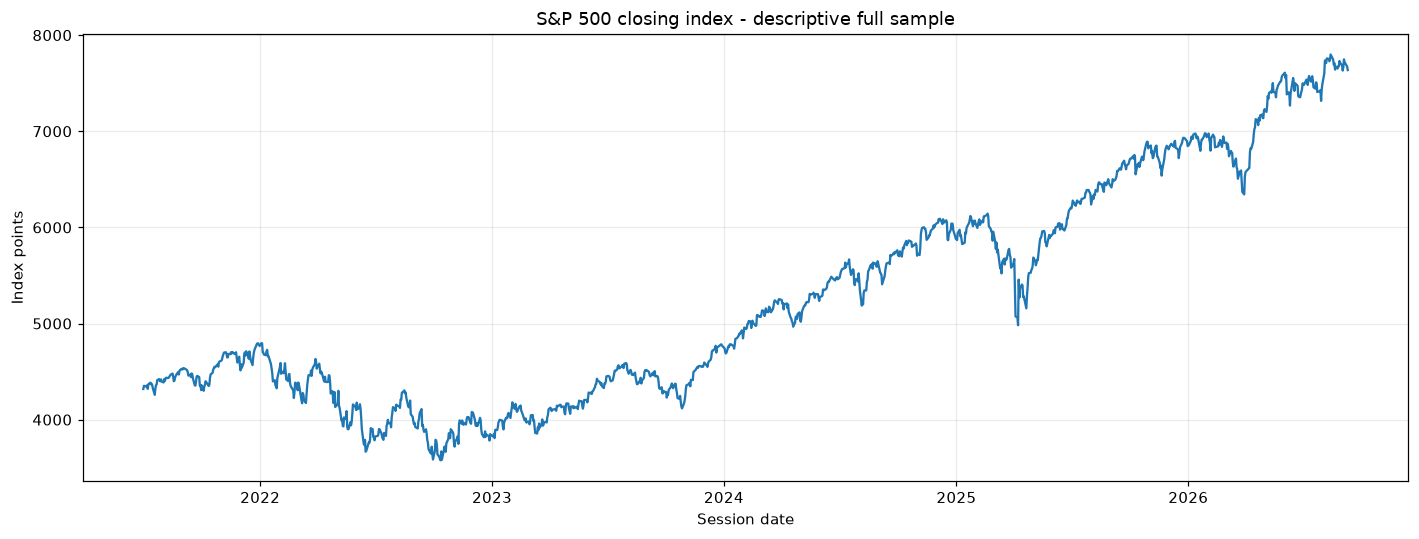

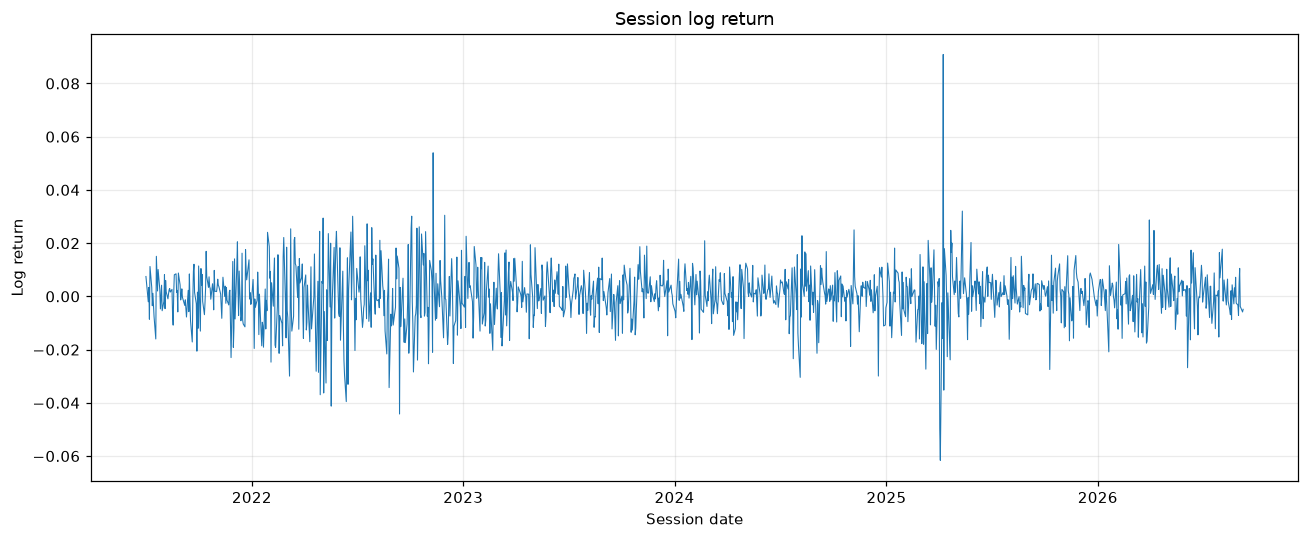

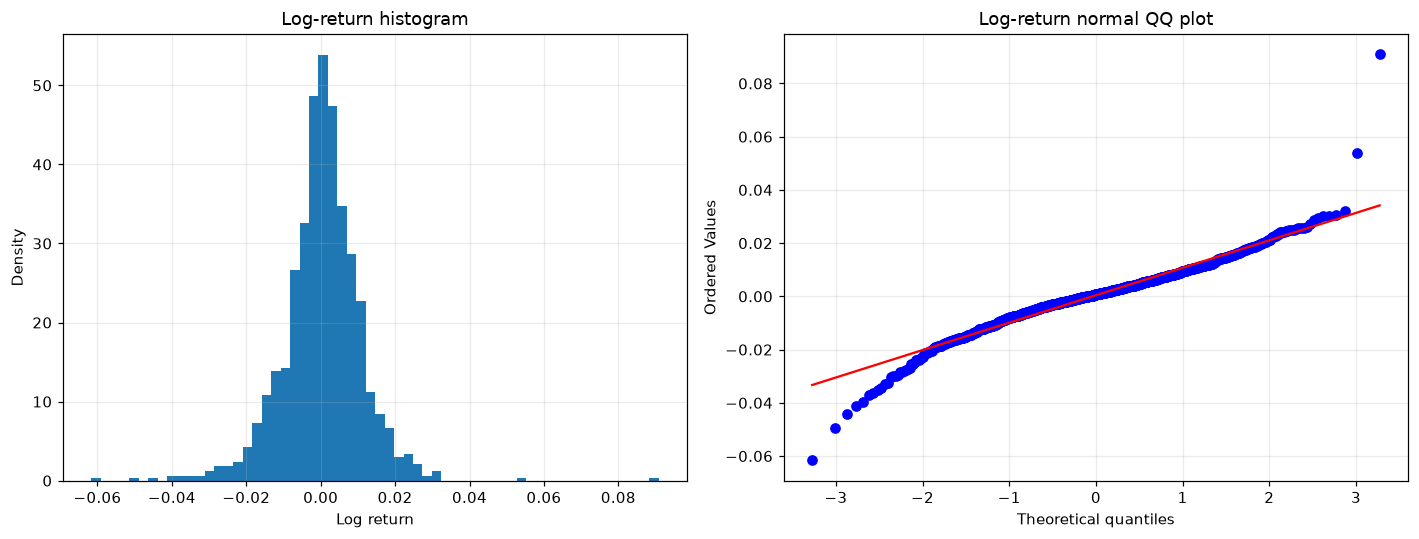

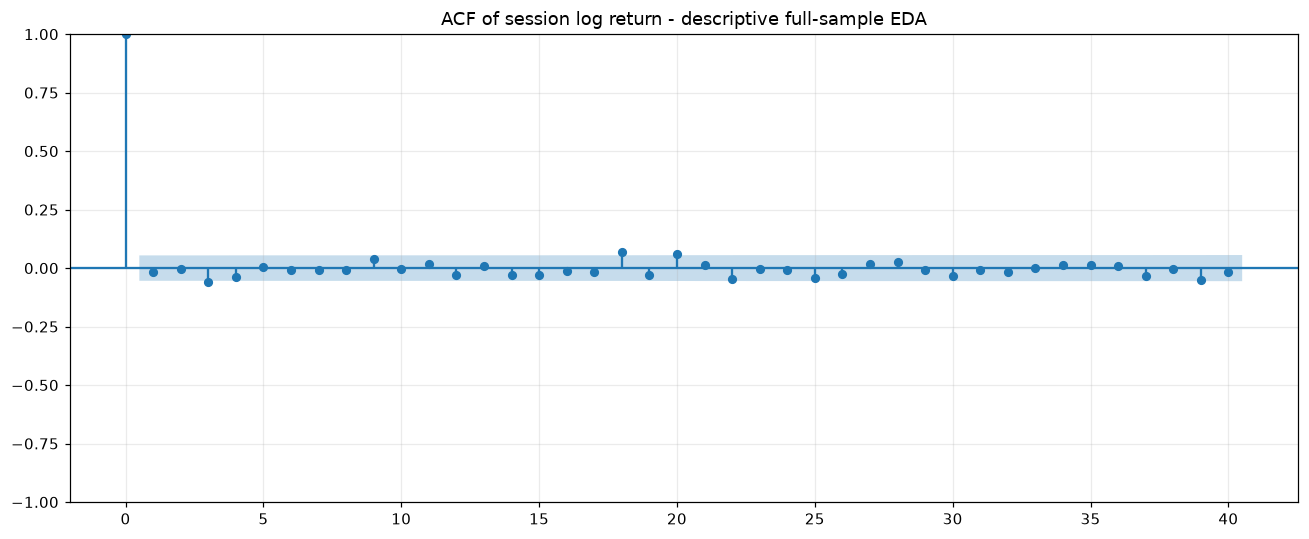

In [3]:
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(df.index,df['Price'])
ax.set(title='S&P 500 closing index - descriptive full sample',ylabel='Index points',xlabel='Session date')
save_figure(fig,'01_raw_index.png')
fig, ax = plt.subplots()
ax.plot(log_ret,linewidth=0.7)
ax.set(title='Session log return',ylabel='Log return',xlabel='Session date')
save_figure(fig,'02_log_return.png')
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].hist(log_ret.dropna(),bins=60,density=True)
axes[0].set(title='Log-return histogram',xlabel='Log return',ylabel='Density')
stats.probplot(log_ret.dropna(),dist='norm',plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig,'03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(),lags=40,ax=ax)
ax.set_title('ACF of session log return - descriptive full-sample EDA')
save_figure(fig,'04_acf_log_return.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [4]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'index points'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,index points,index points,index points
Start,2021-07-01,2021-07-01,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1303,1042,261
Mean,5248.408219,4799.784453,7039.465556
SD,1137.068633,757.331467,389.018605
Min,3577.03,3577.03,6343.72
Q1,4327.49,4175.815,6735.13
Median,4942.81,4536.27,6908.86
Q3,6051.61,5474.625,7420.1


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-26
End,2026-09-09,2025-08-25,2026-09-09
Count,1302,1041,261
Mean,0.000438,0.000383,0.000653
SD,0.010591,0.011152,0.007987
Min,-0.061609,-0.061609,-0.027486
Q1,-0.004709,-0.00506,-0.00375
Median,0.000746,0.000698,0.00108
Q3,0.006175,0.006396,0.005551


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_sessions,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-08-25,1042,3577.03,6468.54,4799.784453,1041,0.000383,0.011152
1,Test,2025-08-26,2026-09-09,261,6343.72,7798.99,7039.465556,261,0.000653,0.007987


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


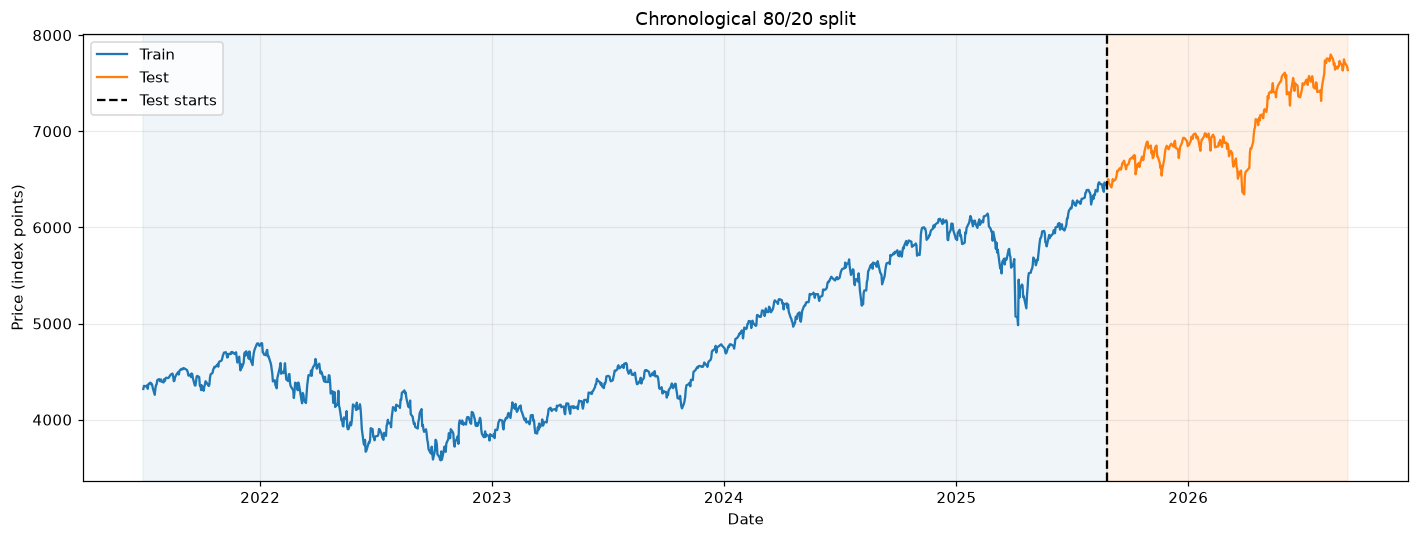

In [5]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert n_train-LOOKBACK-MAX_H > 0 and n_test >= MAX_H
assert df.index[TRAIN_END_IDX] < df.index[n_train]
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_sessions=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (index points)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')

## Step 5 - Train-only scaling

In [6]:
scaler_x_fit_indices = np.arange(1,n_train)
assert scaler_x_fit_indices.max() <= TRAIN_END_IDX
scaler_x = StandardScaler().fit(train_ret.to_numpy().reshape(-1,1))
assert int(scaler_x.n_samples_seen_) == n_train-1
np.testing.assert_allclose(scaler_x.mean_[0],train_ret.mean(),atol=1e-12)
np.testing.assert_allclose(scaler_x.scale_[0],train_ret.std(ddof=0),atol=1e-12)
z = np.full(n,np.nan,dtype=float)
z[1:] = scaler_x.transform(log_ret.iloc[1:].to_numpy().reshape(-1,1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_x_params = dict(mean=float(scaler_x.mean_[0]),std=float(scaler_x.scale_[0]),ddof=0,
    fit_first_index=1,fit_last_index=int(scaler_x_fit_indices.max()),n_samples=int(scaler_x.n_samples_seen_))
print('Frozen input scaler:',scaler_x_params)
assert scaler_x.scale_[0]>0
save_table(pd.DataFrame([scaler_x_params]),"scaler_x_provenance.csv")

Frozen input scaler:

 {'mean': 0.0003834684828426325, 'std': 0.011146597049161362, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1041, 'n_samples': 1041}


## Step 6 - Direct Features and Targets per Horizon
X_t contains z[t-59..t]. y_t^(h) = log_price[t+h]-log_price[t]. Each horizon has its own train origins and target scaler.
All training feature indices and target dates lie in Train. There is no validation set.


In [7]:
training, scaler_y, provenance_rows = {}, {}, []
for h in HORIZONS:
    origins = np.arange(LOOKBACK,TRAIN_END_IDX-h+1)
    input_idx = origins[:,None]-np.arange(LOOKBACK-1,-1,-1)[None,:]
    target_idx = origins+h
    assert input_idx.min()>=1 and input_idx.max()<=TRAIN_END_IDX
    assert target_idx.max()<=TRAIN_END_IDX
    X = z[input_idx]
    y = log_price.iloc[target_idx].to_numpy()-log_price.iloc[origins].to_numpy()
    target_scaler = StandardScaler().fit(y.reshape(-1,1))
    y_scaled = target_scaler.transform(y.reshape(-1,1)).ravel()
    assert len(origins)==TRAIN_END_IDX-LOOKBACK+1-h==n_train-LOOKBACK-h
    assert X.shape==(len(origins),LOOKBACK) and np.isfinite(X).all() and np.isfinite(y_scaled).all()
    assert int(target_scaler.n_samples_seen_)==len(origins)
    scaler_y[h]=target_scaler
    training[h]=dict(origins=origins,input_idx=input_idx,target_idx=target_idx,X=X,y=y,y_scaled=y_scaled)
    provenance_rows.append(dict(h=h,n_train=len(origins),input_min_idx=int(input_idx.min()),
        input_max_idx=int(input_idx.max()),target_max_idx=int(target_idx.max()),
        target_max_date=df.index[target_idx.max()],scaler_y_n=int(target_scaler.n_samples_seen_),
        scaler_y_mean=float(target_scaler.mean_[0]),scaler_y_std=float(target_scaler.scale_[0])))
provenance = pd.DataFrame(provenance_rows)
save_table(provenance,'training_provenance.csv')
display(provenance)

,h,n_train,input_min_idx,input_max_idx,target_max_idx,target_max_date,scaler_y_n,scaler_y_mean,scaler_y_std
0,1,981,1,1040,1041,2025-08-25,981,0.000378,0.011370
1,3,979,1,1038,1041,2025-08-25,979,0.001171,0.019506
2,5,977,1,1036,1041,2025-08-25,977,0.001973,0.024344
3,7,975,1,1034,1041,2025-08-25,975,0.002798,0.028144
4,14,968,1,1027,1041,2025-08-25,968,0.005563,0.039012
5,21,961,1,1020,1041,2025-08-25,961,0.008052,0.046914
6,30,952,1,1011,1041,2025-08-25,952,0.011075,0.055443


## Step 7 - Train-only Analytical Hyperparameters
Use exactly the supplied Cherkassky & Ma (2004) formulas, with population SD (ddof=0):
C=max(abs(mean(y_scaled)+3*std(y_scaled)),abs(mean(y_scaled)-3*std(y_scaled))).
The noise estimate uses k=3 nearest other training samples. Explicitly exclude the row's own index, including in distance ties.
This leave-one-out noise calculation is a fixed training-data formula, not SVR cross-validation or hyperparameter search.
a=n^(1/5)*k; sigma_hat=sqrt(a/(a-1)*MSE_knn); epsilon=3*sigma_hat*sqrt(log(n)/n).
Gamma uses scikit-learn's scale formula 1/(n_features*X.var()). C is expected to be approximately 3 for every horizon because each train target is standardized.


In [8]:
hyper_rows, hyperparameter_origins = [], {}
for h in HORIZONS:
    batch = training[h]
    X,y_scaled = batch['X'],batch['y_scaled']
    sample_n = len(y_scaled)
    assert sample_n > KNN_K and X.var() > 0
    assert batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    hyperparameter_origins[h]=batch['origins'].copy()
    y_mean,y_std = float(y_scaled.mean()),float(y_scaled.std())
    C = max(abs(y_mean+3*y_std),abs(y_mean-3*y_std))
    nn = NearestNeighbors(n_neighbors=KNN_K+1).fit(X)
    _,idx = nn.kneighbors(X)
    neighbor_idx = np.stack([neighbors[neighbors!=row][:KNN_K] for row,neighbors in enumerate(idx)])
    assert neighbor_idx.shape==(sample_n,KNN_K)
    assert (neighbor_idx!=np.arange(sample_n)[:,None]).all()
    y_hat_knn = y_scaled[neighbor_idx].mean(axis=1)
    mse_knn = np.mean((y_scaled-y_hat_knn)**2)
    a = sample_n**(1/5)*KNN_K
    assert a > 1
    sigma_hat = float(np.sqrt(a/(a-1)*mse_knn))
    epsilon = float(3*sigma_hat*np.sqrt(np.log(sample_n)/sample_n))
    gamma_value = float(1/(X.shape[1]*X.var()))
    assert C>0 and epsilon>=0 and np.isfinite([C,sigma_hat,epsilon,gamma_value]).all()
    hyper_rows.append(dict(h=h,n_train=sample_n,y_mean=y_mean,y_std=y_std,C=C,
        sigma_hat=sigma_hat,epsilon=epsilon,gamma_value=gamma_value))
hyperparameters = pd.DataFrame(hyper_rows)
save_table(hyperparameters,'svr_hyperparameters.csv')
display(hyperparameters)

,h,n_train,y_mean,y_std,C,sigma_hat,epsilon,gamma_value
0,1,981,1.810761e-18,1.0,3.0,1.142178,0.287134,0.016012
1,3,979,-3.628921e-18,1.0,3.0,1.136753,0.286020,0.015988
2,5,977,-2.181810e-17,1.0,3.0,1.144898,0.288321,0.015966
3,7,975,2.915047e-17,1.0,3.0,1.136391,0.286429,0.015944
4,14,968,7.340318e-18,1.0,3.0,1.126185,0.284732,0.015871
5,21,961,2.957514e-17,1.0,3.0,1.099139,0.278757,0.015806
6,30,952,2.985474e-17,1.0,3.0,1.100630,0.280260,0.015735


## Step 8 - Fit Once per Horizon and Save Frozen Models


In [9]:
models,fit_records,frozen_hashes = {},[],{}
for h in HORIZONS:
    row = hyperparameters.set_index('h').loc[h]
    batch = training[h]
    model = SVR(kernel=KERNEL,C=float(row['C']),epsilon=float(row['epsilon']),gamma=GAMMA)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(batch['X'],batch['y_scaled'])
    convergence_warning = any(issubclass(w.category,ConvergenceWarning) for w in caught)
    sv_count = int(model.n_support_.sum())
    sv_pct = 100*sv_count/len(batch['X'])
    train_rmse_scaled = float(np.sqrt(np.mean((batch['y_scaled']-model.predict(batch['X']))**2)))
    np.testing.assert_allclose(model._gamma,row['gamma_value'],rtol=1e-12)
    assert model.shape_fit_[0]==len(batch['origins'])
    models[h]=model
    frozen_hashes[h]=joblib.hash((model,scaler_x,scaler_y[h]))
    fit_records.append(dict(h=h,n_SV=sv_count,SV_pct=sv_pct,train_RMSE_scaled=train_rmse_scaled,
        fit_status=int(model.fit_status_),convergence_warning=convergence_warning,
        warnings=' | '.join(str(w.message) for w in caught)))
    print(f'Fitted h={h}: {sv_count} support vectors ({sv_pct:.2f}%)',flush=True)
fit_audit = pd.DataFrame(fit_records)
hyperparameters = hyperparameters.merge(fit_audit,on='h',validate='one_to_one')
save_table(hyperparameters,'svr_hyperparameters.csv')
display(hyperparameters)
assert not fit_audit['convergence_warning'].any()
assert fit_audit['fit_status'].eq(0).all() and fit_audit['SV_pct'].between(0,100).all()

Fitted h=1: 721 support vectors (73.50%)


Fitted h=3: 714 support vectors (72.93%)


Fitted h=5: 712 support vectors (72.88%)

Fitted h=7: 739 support vectors (75.79%)

Fitted h=14: 791 support vectors (81.71%)


Fitted h=21: 775 support vectors (80.65%)


Fitted h=30: 788 support vectors (82.77%)


,h,n_train,y_mean,y_std,C,sigma_hat,epsilon,gamma_value,n_SV,SV_pct,train_RMSE_scaled,fit_status,convergence_warning,warnings
0,1,981,1.810761e-18,1.0,3.0,1.142178,0.287134,0.016012,721,73.496432,0.439730,0,False,
1,3,979,-3.628921e-18,1.0,3.0,1.136753,0.286020,0.015988,714,72.931563,0.434590,0,False,
2,5,977,-2.181810e-17,1.0,3.0,1.144898,0.288321,0.015966,712,72.876151,0.427179,0,False,
3,7,975,2.915047e-17,1.0,3.0,1.136391,0.286429,0.015944,739,75.794872,0.418782,0,False,
4,14,968,7.340318e-18,1.0,3.0,1.126185,0.284732,0.015871,791,81.714876,0.394918,0,False,
5,21,961,2.957514e-17,1.0,3.0,1.099139,0.278757,0.015806,775,80.645161,0.371334,0,False,
6,30,952,2.985474e-17,1.0,3.0,1.100630,0.280260,0.015735,788,82.773109,0.400337,0,False,


## Step 9 - Rolling-origin Test Forecasts with Fixed Models
Origins are n_train-1..n-2; each input uses only the previous 60 observed returns through its own origin.
Each horizon predicts eligible origins in one batch. Inverse-transform its cumulative-return target, then multiply the origin price by exp(predicted cumulative return).
No model, scaler, or hyperparameter is re-estimated during inference.


In [10]:
test_origins = np.arange(TRAIN_END_IDX,n-1)
forecast_rows,predicted_cumulative_returns = [],{}
for h in HORIZONS:
    origins = test_origins[test_origins+h<n]
    input_idx = origins[:,None]-np.arange(LOOKBACK-1,-1,-1)[None,:]
    assert (input_idx<=origins[:,None]).all() and input_idx.min()>=1
    X_test = z[input_idx]
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
    y_hat_scaled = models[h].predict(X_test)
    r_hat = scaler_y[h].inverse_transform(y_hat_scaled.reshape(-1,1)).ravel()
    predicted_cumulative_returns[h]=r_hat
    prices_origin = df['Price'].iloc[origins].to_numpy()
    prices_hat = prices_origin*np.exp(r_hat)
    for pos,origin in enumerate(origins):
        forecast_rows.append(dict(origin_date=df.index[origin],h=h,target_date=df.index[origin+h],
            price_origin=prices_origin[pos],actual=df['Price'].iloc[origin+h],svr_fc=prices_hat[pos]))
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert (df.index.get_indexer(forecasts['target_date'])-df.index.get_indexer(forecasts['origin_date'])==forecasts['h'].to_numpy()).all()
assert forecasts['target_date'].between(df.index[n_train],df.index[-1]).all()
save_table(forecasts,'forecasts_long.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())

,n_points
h,
1,261
3,259
5,257
7,255
14,248
21,241
30,232


### 9.1 Test Forecast Tables by Horizon


In [11]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'**h={h} trading sessions, {len(group)} test forecasts**'))
    show_scroll_table(group)

**h=1 trading sessions, 261 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,1,2025-08-26,"6,439.3200","6,465.9400","6,452.7235"
2025-08-26,1,2025-08-27,"6,465.9400","6,481.4000","6,440.6749"
2025-08-27,1,2025-08-28,"6,481.4000","6,501.8600","6,480.3402"
2025-08-28,1,2025-08-29,"6,501.8600","6,460.2600","6,500.7579"
2025-08-29,1,2025-09-02,"6,460.2600","6,415.5400","6,473.4797"
2025-09-02,1,2025-09-03,"6,415.5400","6,448.2600","6,449.5955"
2025-09-03,1,2025-09-04,"6,448.2600","6,502.0800","6,449.3902"
2025-09-04,1,2025-09-05,"6,502.0800","6,481.5000","6,524.4954"
2025-09-05,1,2025-09-08,"6,481.5000","6,495.1500","6,517.4284"
2025-09-08,1,2025-09-09,"6,495.1500","6,512.6100","6,520.1598"


**h=3 trading sessions, 259 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,3,2025-08-28,"6,439.3200","6,501.8600","6,443.7354"
2025-08-26,3,2025-08-29,"6,465.9400","6,460.2600","6,420.4340"
2025-08-27,3,2025-09-02,"6,481.4000","6,415.5400","6,488.3166"
2025-08-28,3,2025-09-03,"6,501.8600","6,448.2600","6,528.7460"
2025-08-29,3,2025-09-04,"6,460.2600","6,502.0800","6,506.9950"
2025-09-02,3,2025-09-05,"6,415.5400","6,481.5000","6,462.8243"
2025-09-03,3,2025-09-08,"6,448.2600","6,495.1500","6,511.0135"
2025-09-04,3,2025-09-09,"6,502.0800","6,512.6100","6,576.0935"
2025-09-05,3,2025-09-10,"6,481.5000","6,532.0400","6,553.2408"
2025-09-08,3,2025-09-11,"6,495.1500","6,587.4700","6,531.2976"


**h=5 trading sessions, 257 test forecasts**

...

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,14,2025-09-15,"6,439.3200","6,615.2800","6,541.1760"
2025-08-26,14,2025-09-16,"6,465.9400","6,606.7600","6,534.9378"
2025-08-27,14,2025-09-17,"6,481.4000","6,600.3500","6,547.2813"
2025-08-28,14,2025-09-18,"6,501.8600","6,631.9600","6,613.6834"
2025-08-29,14,2025-09-19,"6,460.2600","6,664.3600","6,520.0180"
2025-09-02,14,2025-09-22,"6,415.5400","6,693.7500","6,529.7915"
2025-09-03,14,2025-09-23,"6,448.2600","6,656.9200","6,544.9448"
2025-09-04,14,2025-09-24,"6,502.0800","6,637.9700","6,604.0570"
2025-09-05,14,2025-09-25,"6,481.5000","6,604.7200","6,546.4699"
2025-09-08,14,2025-09-26,"6,495.1500","6,643.7000","6,554.9431"


**h=21 trading sessions, 241 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,21,2025-09-24,"6,439.3200","6,637.9700","6,543.5858"
2025-08-26,21,2025-09-25,"6,465.9400","6,604.7200","6,543.6142"
2025-08-27,21,2025-09-26,"6,481.4000","6,643.7000","6,616.8772"
2025-08-28,21,2025-09-29,"6,501.8600","6,661.2100","6,603.6468"
2025-08-29,21,2025-09-30,"6,460.2600","6,688.4600","6,602.7199"
2025-09-02,21,2025-10-01,"6,415.5400","6,711.2000","6,567.8393"
2025-09-03,21,2025-10-02,"6,448.2600","6,715.3500","6,568.6874"
2025-09-04,21,2025-10-03,"6,502.0800","6,715.7900","6,597.3528"
2025-09-05,21,2025-10-06,"6,481.5000","6,740.2800","6,549.1068"
2025-09-08,21,2025-10-07,"6,495.1500","6,714.5900","6,556.1981"


**h=30 trading sessions, 232 test forecasts**

origin_date,h,target_date,price_origin,actual,svr_fc
2025-08-25,30,2025-10-07,"6,439.3200","6,714.5900","6,599.2665"
2025-08-26,30,2025-10-08,"6,465.9400","6,753.7200","6,594.8057"
2025-08-27,30,2025-10-09,"6,481.4000","6,735.1100","6,632.9225"
2025-08-28,30,2025-10-10,"6,501.8600","6,552.5100","6,614.1984"
2025-08-29,30,2025-10-13,"6,460.2600","6,654.7200","6,593.2159"
2025-09-02,30,2025-10-14,"6,415.5400","6,644.3100","6,559.7685"
2025-09-03,30,2025-10-15,"6,448.2600","6,671.0600","6,561.3309"
2025-09-04,30,2025-10-16,"6,502.0800","6,629.0700","6,638.2078"
2025-09-05,30,2025-10-17,"6,481.5000","6,664.0100","6,548.9317"
2025-09-08,30,2025-10-20,"6,495.1500","6,735.1300","6,570.6646"


### 9.2 Future Forecasts from the Last Observed Date
One row per horizon uses a common latest origin. These future targets have no actual prices in the source and are excluded from test metrics.
These are fixed-model point forecasts; no prediction interval is claimed.


In [12]:
latest_input = z[n-LOOKBACK:n].reshape(1,LOOKBACK)
future_rows=[]
for h in HORIZONS:
    predicted_scaled = models[h].predict(latest_input)
    r_hat = float(scaler_y[h].inverse_transform(predicted_scaled.reshape(-1,1))[0,0])
    future_rows.append(dict(origin_date=df.index[-1],h=h,target_date=future_dates[h-1],
        price_origin=float(df['Price'].iloc[-1]),svr_fc=float(df['Price'].iloc[-1])*np.exp(r_hat)))
    assert joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
future_forecasts = pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)

origin_date,h,target_date,price_origin,svr_fc
2026-09-09,1,2026-09-10,"7,636.3600","7,674.5866"
2026-09-09,3,2026-09-14,"7,636.3600","7,716.1317"
2026-09-09,5,2026-09-16,"7,636.3600","7,745.1857"
2026-09-09,7,2026-09-18,"7,636.3600","7,739.2750"
2026-09-09,14,2026-09-29,"7,636.3600","7,744.0735"
2026-09-09,21,2026-10-08,"7,636.3600","7,805.5296"
2026-09-09,30,2026-10-21,"7,636.3600","7,946.6932"


### 9.3 Daily future forecast tables - next 7 and 30 steps

Horizons count NYSE trading sessions and retain the existing holiday calendar.

Reuses original direct-horizon models; fits only missing daily horizons on Train with the original settings/prescription. No interpolation, validation, Test tuning or refitting of existing models. No calibrated prediction intervals are supplied.

Both complete tables are embedded below and retained via the existing notebook-only save_table helper.


In [13]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
# Reuse original direct-horizon models; fit only missing horizons on Train.
daily_models = {h: models[h] for h in HORIZONS}
daily_hashes = {h: frozen_hashes[h] for h in HORIZONS}
daily_fit_rows = []
daily_target_scalers = {h: scaler_y[h] for h in HORIZONS}
for h in range(1, daily_steps + 1):
    if h in models:
        continue
    origins = np.arange(LOOKBACK, TRAIN_END_IDX - h + 1)
    input_idx = origins[:, None] - np.arange(LOOKBACK - 1, -1, -1)[None, :]
    target_idx = origins + h
    assert input_idx.min() >= 1 and target_idx.max() == TRAIN_END_IDX
    assert (input_idx <= origins[:, None]).all()
    assert len(origins) == n_train - LOOKBACK - h
    X = z[input_idx]
    y = np.asarray(log_price)[target_idx] - np.asarray(log_price)[origins]
    assert np.isfinite(X).all() and np.isfinite(y).all()
    target_scaler = StandardScaler().fit(y[:, None])
    ys = target_scaler.transform(y[:, None]).ravel()
    k = KNN_K
    assert len(y) > k and X.var() > 0 and ys.std() > 0
    neighbors = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)
    others = np.stack([v[v != i][:k] for i, v in enumerate(neighbors)])
    assert others.shape == (len(y), k) and (others != np.arange(len(y))[:, None]).all()
    mse_knn = np.mean((ys - ys[others].mean(axis=1))**2)
    a = len(y)**.2*k
    assert a > 1
    sigma_hat = np.sqrt(a/(a-1)*mse_knn)
    C = max(abs(ys.mean() + 3*ys.std(ddof=0)), abs(ys.mean() - 3*ys.std(ddof=0)))
    epsilon = 3*sigma_hat*np.sqrt(np.log(len(y))/len(y))
    assert C > 0 and epsilon >= 0 and np.isfinite([C, epsilon, sigma_hat]).all()
    model = SVR(kernel=KERNEL, gamma=GAMMA, C=C, epsilon=epsilon)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, ys)
    convergence_warning = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    assert model.fit_status_ == 0 and not convergence_warning
    assert int(target_scaler.n_samples_seen_) == len(y)
    daily_target_scalers[h] = target_scaler
    fit_details = dict(C=float(C), epsilon=float(epsilon), sigma_hat=float(sigma_hat),
        gamma=float(model._gamma), fit_status=int(model.fit_status_),
        convergence_warning=convergence_warning, target_scaler_n=int(target_scaler.n_samples_seen_))
    daily_models[h] = model
    daily_hashes[h] = joblib.hash((model, scaler_x, target_scaler))
    daily_fit_rows.append(dict(h=h, n_train=len(origins), input_max_idx=int(input_idx.max()),
        target_max_idx=int(target_idx.max()), target_max_date=df.index[target_idx.max()],
        warnings=' | '.join(str(w.message) for w in caught), **fit_details))
daily_additional_fit_audit = pd.DataFrame(daily_fit_rows)
save_table(daily_additional_fit_audit, 'daily_additional_fit_audit.csv')
display(Markdown('**Train-only fitting audit for additional daily horizons**'))
show_scroll_table(daily_additional_fit_audit)
daily_idx = n - 1 - np.arange(LOOKBACK - 1, -1, -1)
daily_input = z[daily_idx].reshape(1, LOOKBACK)
daily_values = []
for h in range(1, daily_steps + 1):
    model = daily_models[h]
    target_scaler = daily_target_scalers[h]
    assert joblib.hash((model, scaler_x, target_scaler)) == daily_hashes[h]
    prediction = model.predict(daily_input)
    cumulative_return = float(target_scaler.inverse_transform(prediction[:, None])[0, 0])
    daily_values.append(daily_origin_price*np.exp(cumulative_return))
    assert joblib.hash((model, scaler_x, target_scaler)) == daily_hashes[h]
future_forecast_daily['svr_fc'] = daily_values
daily_forecast_columns = ['svr_fc']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['svr_fc']],
    future_forecasts.set_index('h').loc[HORIZONS, ['svr_fc']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} NYSE trading sessions - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} index points**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all(f'future_forecast_daily_{days}d.csv' in notebook_tables for days in DAILY_FORECAST_WINDOWS)


**Train-only fitting audit for additional daily horizons**

h,n_train,input_max_idx,target_max_idx,target_max_date,warnings,C,epsilon,sigma_hat,gamma,fit_status,convergence_warning,target_scaler_n
2,980,1039,1041,2025-08-25,,3.0000,0.2840,1.1293,0.0160,0,False,980
4,978,1037,1041,2025-08-25,,3.0000,0.2859,1.1356,0.0160,0,False,978
6,976,1035,1041,2025-08-25,,3.0000,0.2879,1.1429,0.0160,0,False,976
8,974,1033,1041,2025-08-25,,3.0000,0.2863,1.1355,0.0159,0,False,974
9,973,1032,1041,2025-08-25,,3.0000,0.2883,1.1428,0.0159,0,False,973
10,972,1031,1041,2025-08-25,,3.0000,0.2903,1.1502,0.0159,0,False,972
11,971,1030,1041,2025-08-25,,3.0000,0.2908,1.1516,0.0159,0,False,971
12,970,1029,1041,2025-08-25,,3.0000,0.2875,1.1381,0.0159,0,False,970
13,969,1028,1041,2025-08-25,,3.0000,0.2853,1.1291,0.0159,0,False,969
15,967,1026,1041,2025-08-25,,3.0000,0.2837,1.1217,0.0159,0,False,967


**Next 7 NYSE trading sessions - origin 2026-09-09, last observed price 7,636.360000 index points**

origin_date,h,target_date,day_of_week,price_origin,svr_fc
2026-09-09,1,2026-09-10,Thursday,"7,636.360000","7,674.586572"
2026-09-09,2,2026-09-11,Friday,"7,636.360000","7,715.863281"
2026-09-09,3,2026-09-14,Monday,"7,636.360000","7,716.131729"
2026-09-09,4,2026-09-15,Tuesday,"7,636.360000","7,712.583307"
2026-09-09,5,2026-09-16,Wednesday,"7,636.360000","7,745.185686"
2026-09-09,6,2026-09-17,Thursday,"7,636.360000","7,744.720188"
2026-09-09,7,2026-09-18,Friday,"7,636.360000","7,739.274981"


**Next 30 NYSE trading sessions - origin 2026-09-09, last observed price 7,636.360000 index points**

origin_date,h,target_date,day_of_week,price_origin,svr_fc
2026-09-09,1,2026-09-10,Thursday,"7,636.360000","7,674.586572"
2026-09-09,2,2026-09-11,Friday,"7,636.360000","7,715.863281"
2026-09-09,3,2026-09-14,Monday,"7,636.360000","7,716.131729"
2026-09-09,4,2026-09-15,Tuesday,"7,636.360000","7,712.583307"
2026-09-09,5,2026-09-16,Wednesday,"7,636.360000","7,745.185686"
2026-09-09,6,2026-09-17,Thursday,"7,636.360000","7,744.720188"
2026-09-09,7,2026-09-18,Friday,"7,636.360000","7,739.274981"
2026-09-09,8,2026-09-21,Monday,"7,636.360000","7,768.312185"
2026-09-09,9,2026-09-22,Tuesday,"7,636.360000","7,751.671330"
2026-09-09,10,2026-09-23,Wednesday,"7,636.360000","7,785.204022"


## Step 10 - RMSE and MAPE Evaluation (SVR Only)
Sanity checks stop and display invalid rows without clipping or retuning. Metrics compare historical test target prices with their aligned forecasts in index points.


In [14]:
for name,frame in [('test',forecasts),('future',future_forecasts)]:
    valid = np.isfinite(frame['svr_fc']) & frame['svr_fc'].gt(0)
    if not valid.all():
        bad = frame.loc[~valid]
        display(bad)
        save_table(bad,f'forecast_sanity_failures_{name}.csv')
    assert valid.all(), f'Invalid {name} forecasts; stop without clipping or retuning'
def rmse(actual,fc): return float(np.sqrt(np.mean((np.asarray(actual)-np.asarray(fc))**2)))
def mape(actual,fc):
    actual=np.asarray(actual,dtype=float)
    assert (actual>0).all()
    return float(100*np.mean(np.abs((actual-np.asarray(fc))/actual)))
evaluation = pd.DataFrame([dict(h=h,n_points=len(group),RMSE=rmse(group['actual'],group['svr_fc']),
    MAPE=mape(group['actual'],group['svr_fc']))
    for h in HORIZONS for group in [forecasts.loc[forecasts['h'].eq(h)]]])
save_table(evaluation,'evaluation_by_horizon.csv')
display(evaluation.style.format({'RMSE':'{:,.2f}','MAPE':'{:.2f}'}).hide(axis='index'))

h,n_points,RMSE,MAPE
1,261,58.78,0.64
3,259,100.26,1.12
5,257,121.56,1.35
7,255,146.56,1.60
14,248,204.97,2.24
21,241,248.82,2.68
30,232,280.26,2.92


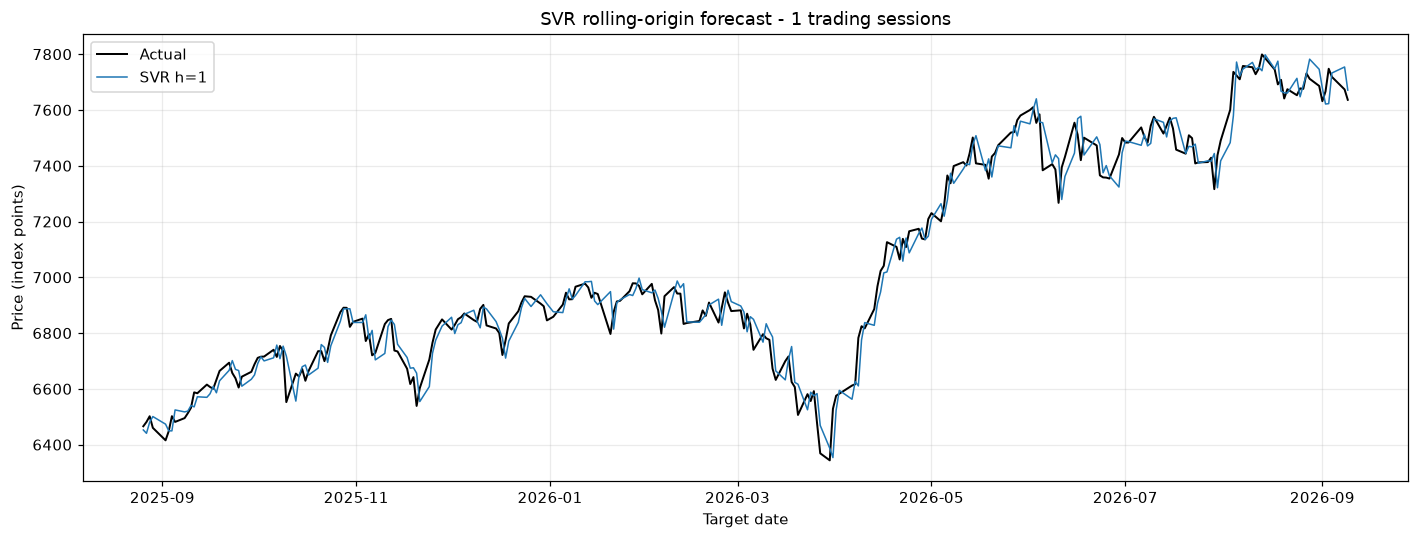

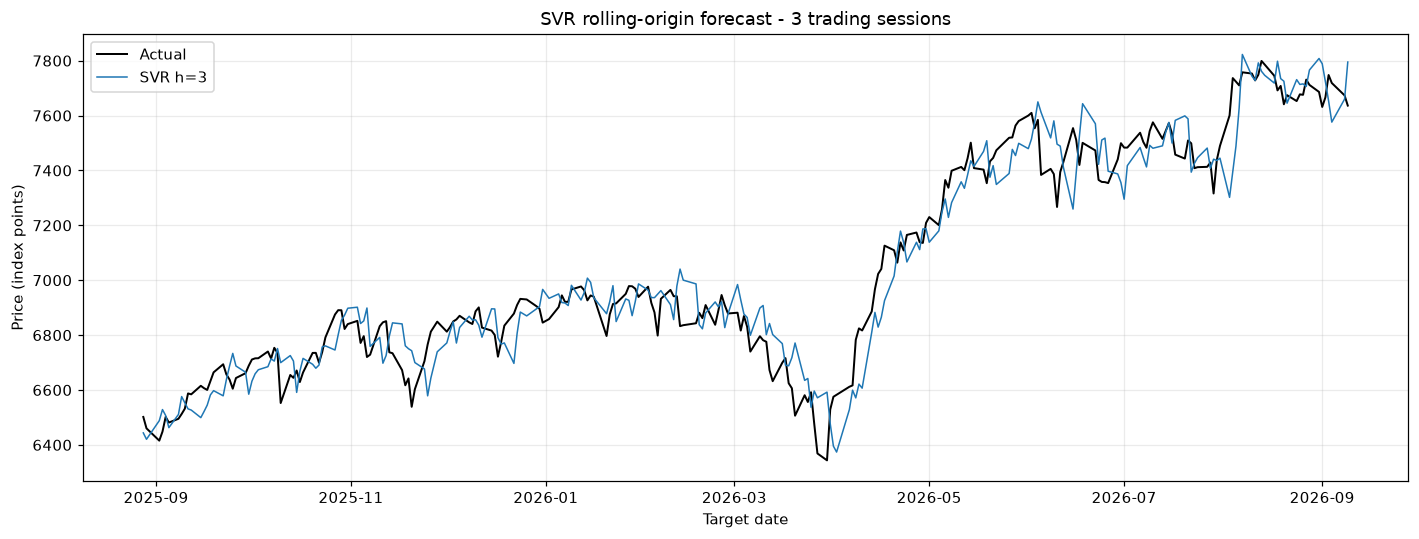

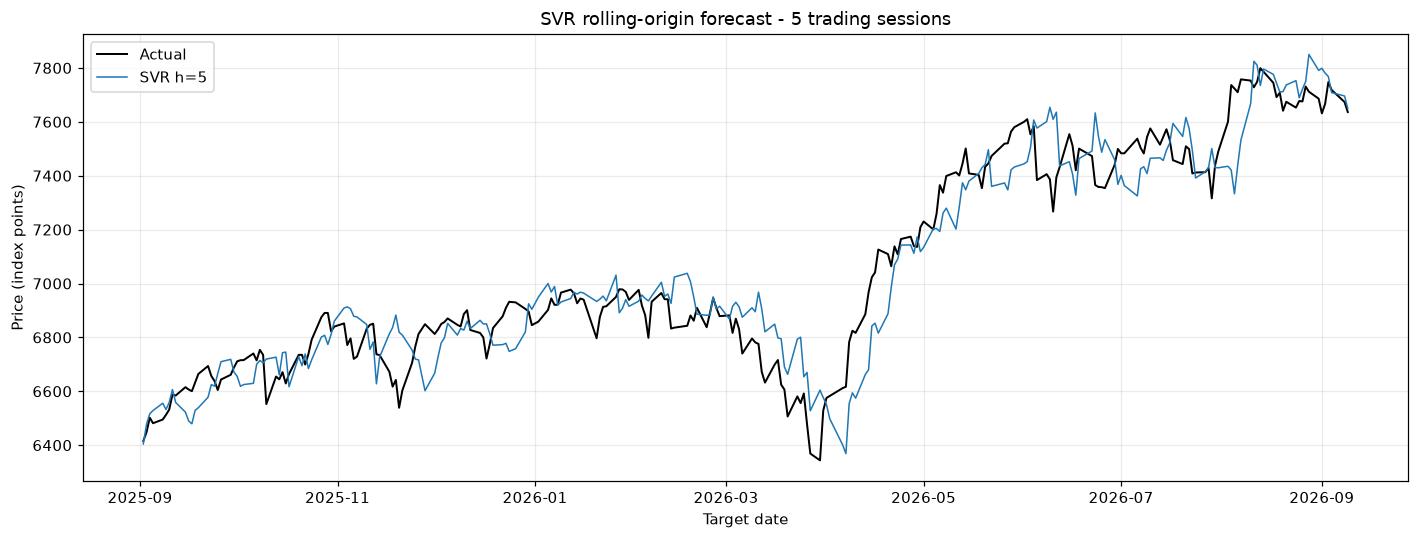

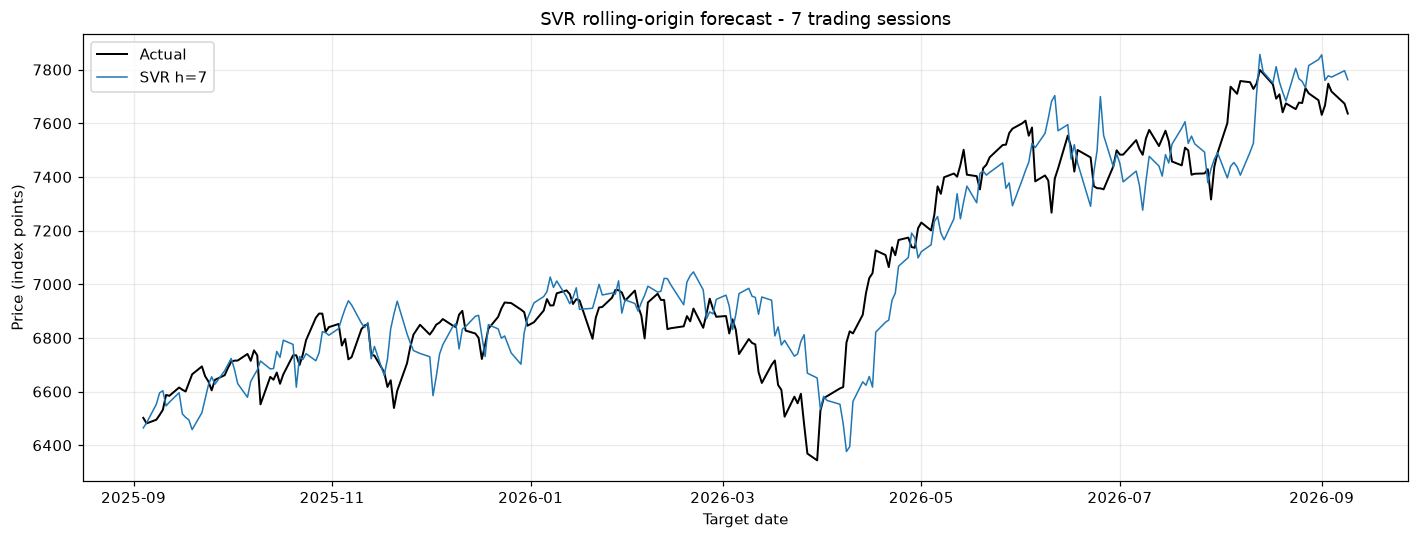

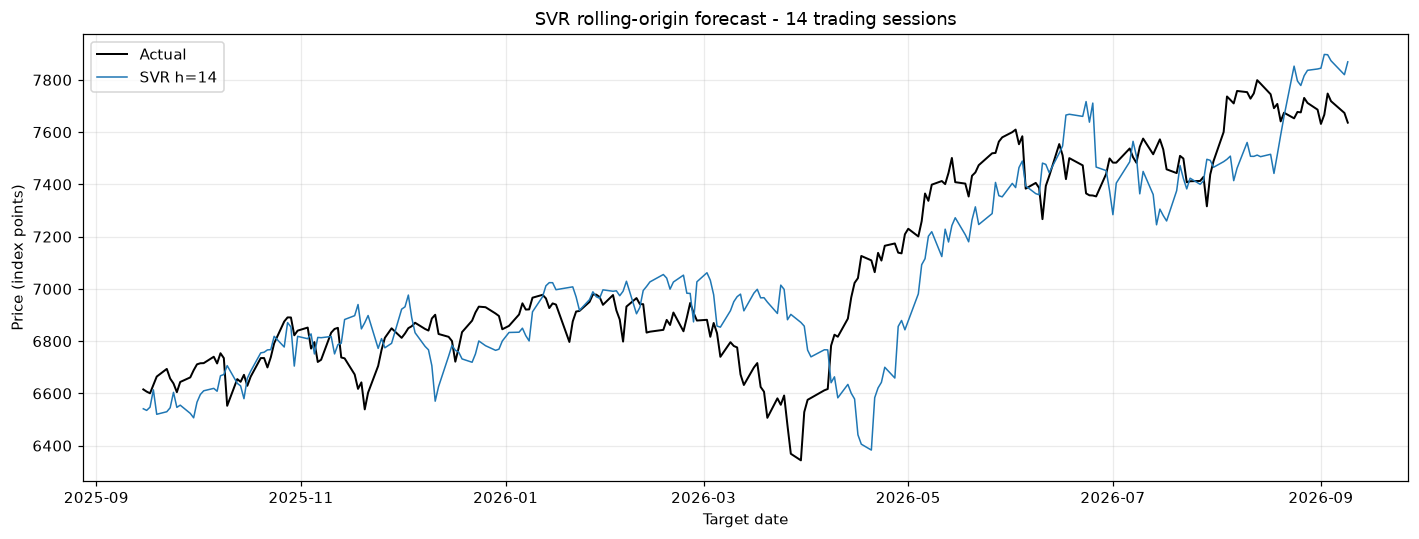

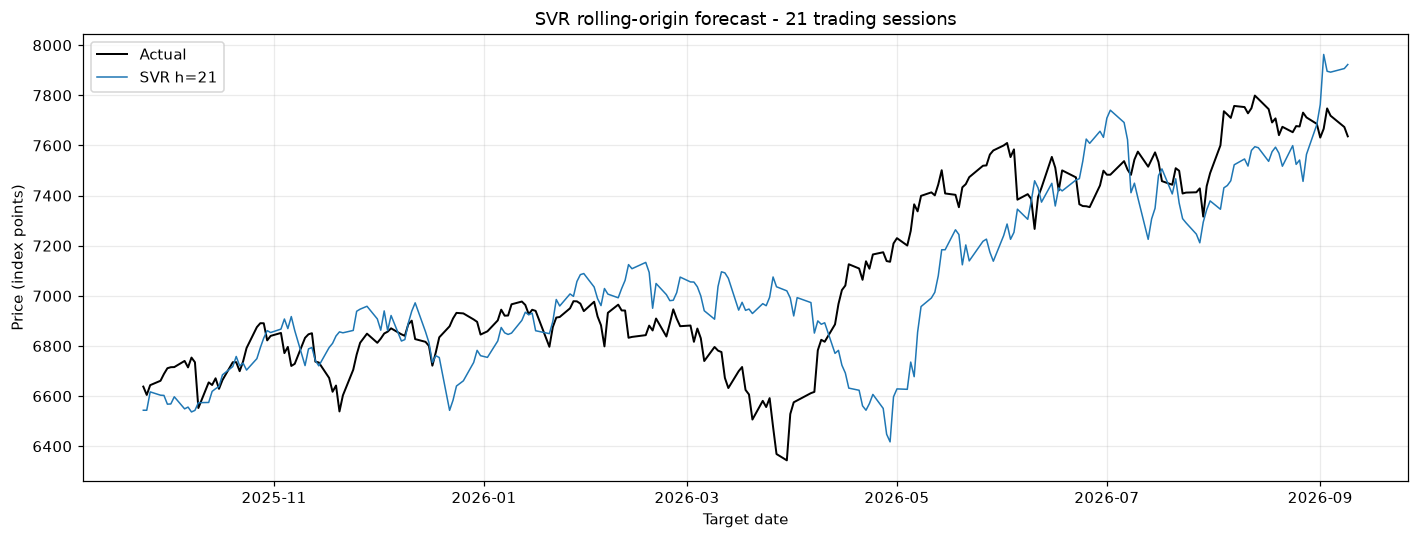

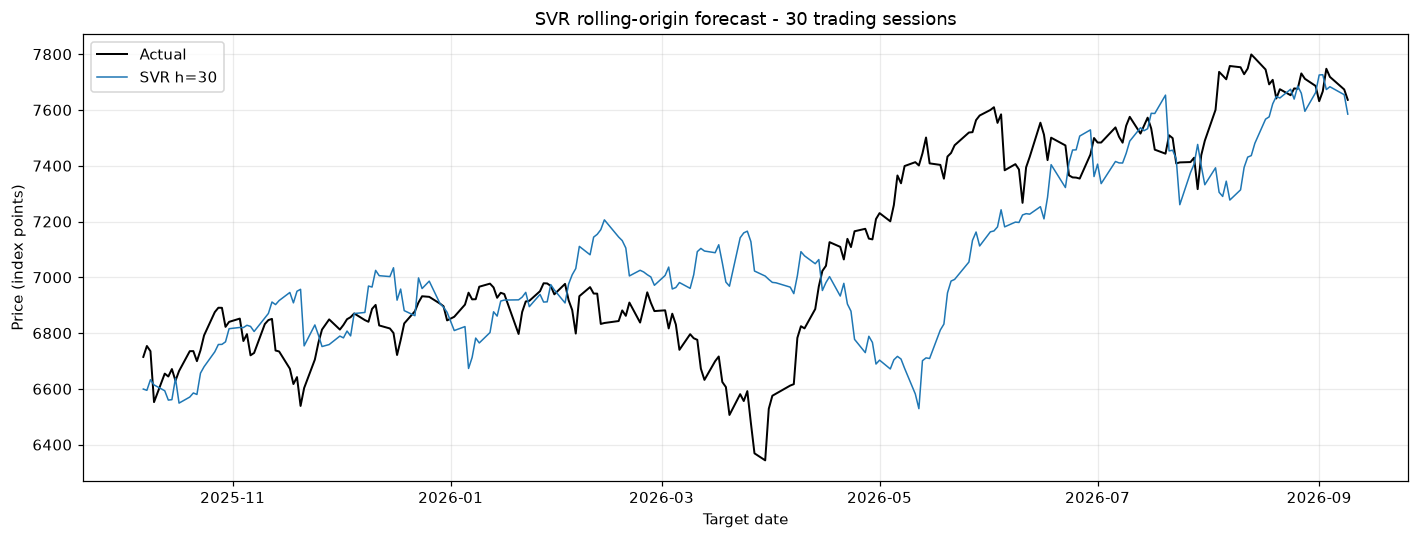

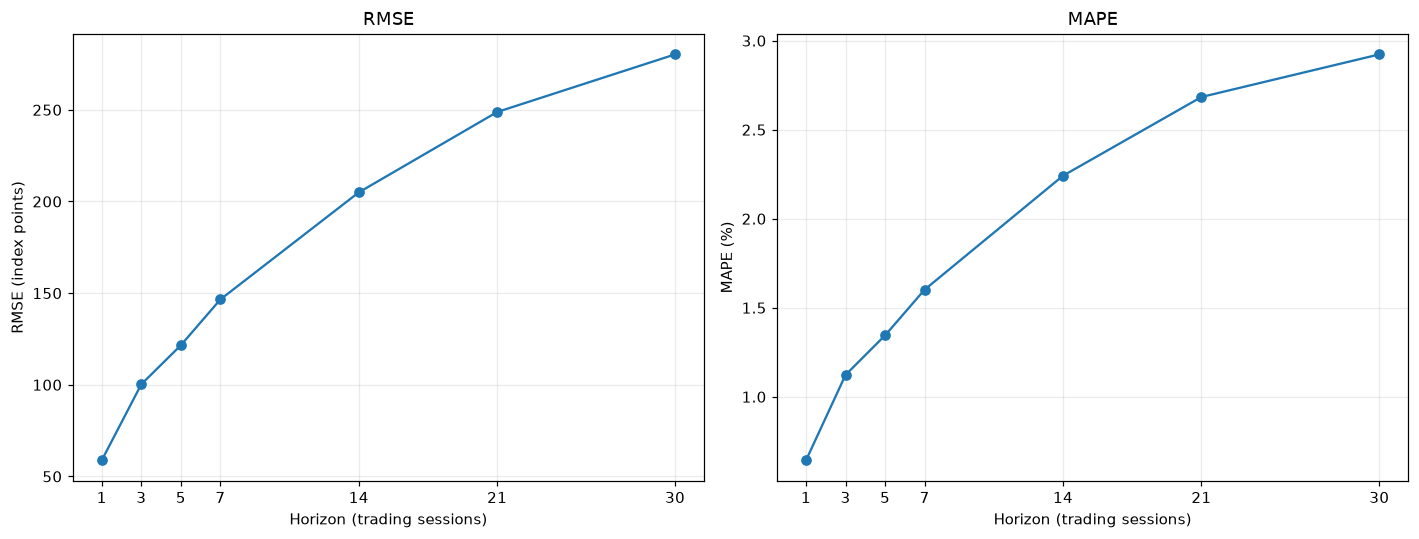

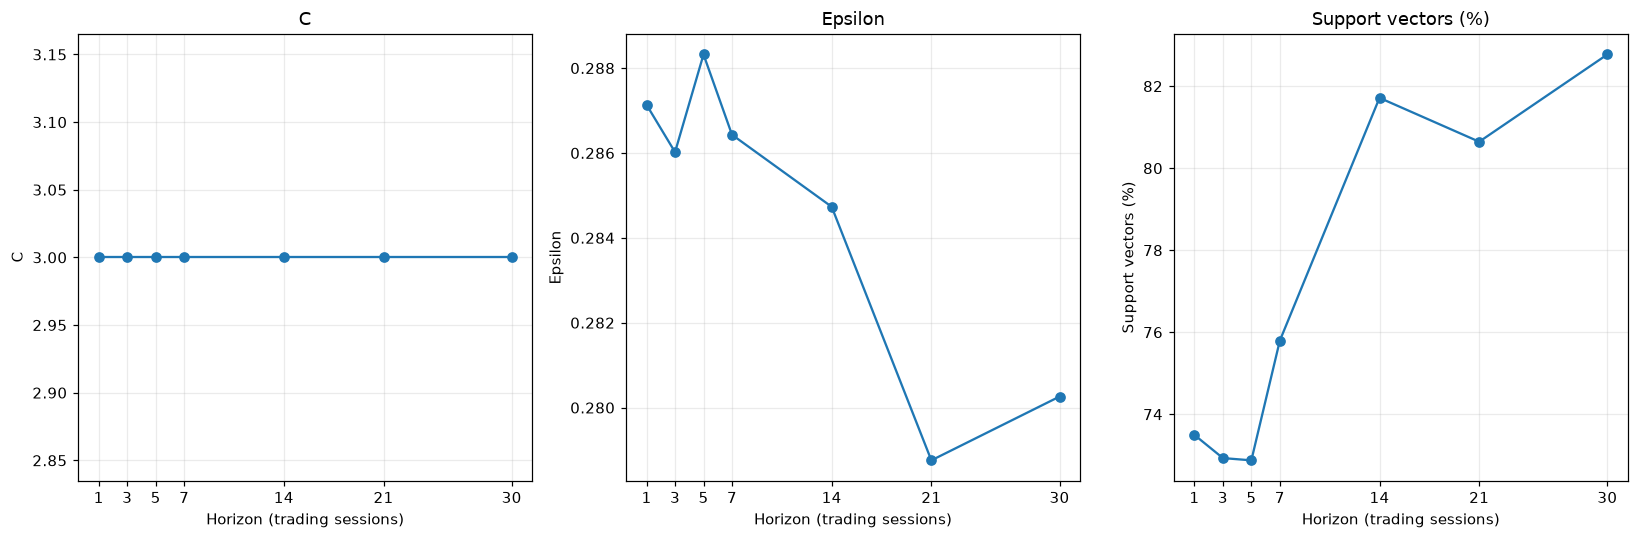

In [15]:
for h in HORIZONS:
    group=forecasts.loc[forecasts['h'].eq(h)]
    fig,ax=plt.subplots(figsize=(13,5))
    ax.plot(group['target_date'],group['actual'],label='Actual',color='black',linewidth=1.3)
    ax.plot(group['target_date'],group['svr_fc'],label=f'SVR h={h}',linewidth=1)
    ax.set(title=f'SVR rolling-origin forecast - {h} trading sessions',xlabel='Target date',ylabel='Price (index points)')
    ax.legend(); save_figure(fig,f'06_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],['index points','%']):
    ax.plot(evaluation['h'],evaluation[metric],marker='o')
    ax.set(title=metric,xlabel='Horizon (trading sessions)',ylabel=f'{metric} ({unit})',xticks=HORIZONS)
save_figure(fig,'07_error_vs_horizon.png')
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,column,label in zip(axes,['C','epsilon','SV_pct'],['C','Epsilon','Support vectors (%)']):
    ax.plot(hyperparameters['h'],hyperparameters[column],marker='o')
    ax.set(title=label,xlabel='Horizon (trading sessions)',ylabel=label,xticks=HORIZONS)
save_figure(fig,'08_hyperparameters_by_horizon.png')

## Step 11 - Assumption and Process Checks
Group A structural and fitting requirements must pass. Train/test return mean and SD are reported descriptively because no acceptance threshold was supplied; no test distribution result changes the model.
Group B uses only h=1 test errors in unscaled log-return units. Higher-horizon targets overlap, so their autocorrelation would partly arise by construction. Diagnostics are reporting-only, not model rejection criteria.


Group A finite-loss and structural checks are enforced. Loss reduction and distribution/seed stability are descriptive; no new threshold is imposed. Group B diagnoses h=1 Test log-return errors only and never changes the fitted design.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Input scaler excludes test,1041.000000,NaN,PASS,
2,A,Train features/targets exclude test: h=1,1041.000000,NaN,PASS,
3,A,Target scaler excludes test: h=1,981.000000,NaN,PASS,
4,A,Hyperparameters use train only: h=1,981.000000,NaN,PASS,
5,A,Fit successful: h=1,73.496432,NaN,PASS,Statistic=%SV; n_SV=721; no ConvergenceWarning...
6,A,Model/scalers fixed in inference: h=1,1.000000,NaN,PASS,
7,A,Train features/targets exclude test: h=3,1041.000000,NaN,PASS,
8,A,Target scaler excludes test: h=3,979.000000,NaN,PASS,
9,A,Hyperparameters use train only: h=3,979.000000,NaN,PASS,


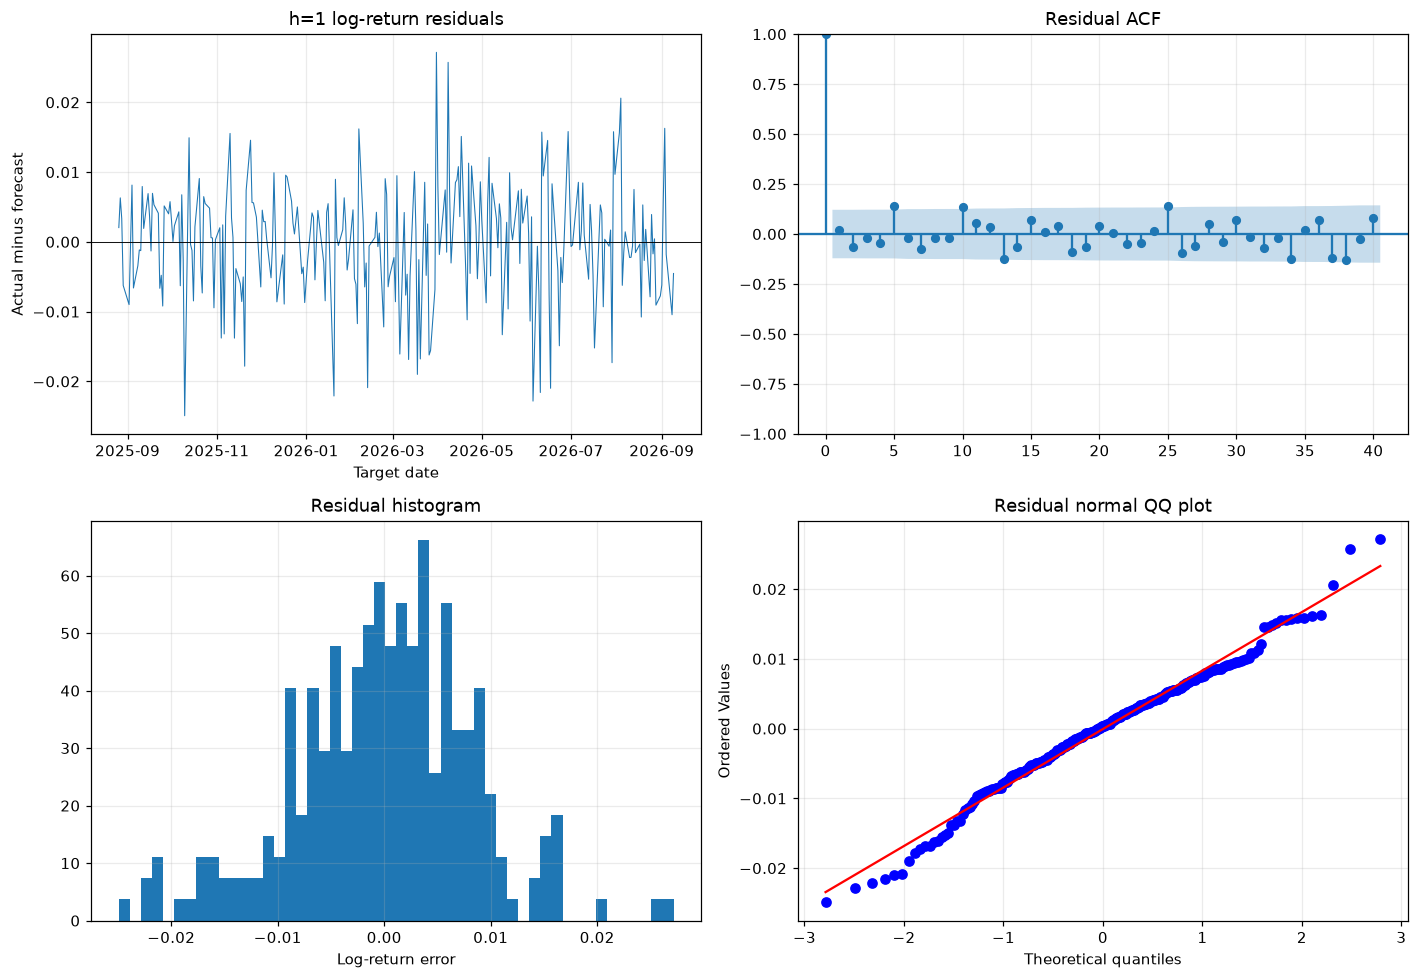

In [16]:
checks=[]
def add_check(group,check,statistic=np.nan,p_value=np.nan,passed=None,note=''):
    checks.append({'group':group,'check':check,'statistic':statistic,'p_value':p_value,
        'pass/fail':'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL'),'note':note})
ordered=df.index.is_monotonic_increasing and df.index.is_unique
add_check('A','Chronological unique dates',int(ordered),passed=ordered)
assert ordered
add_check('A','Input scaler excludes test',int(scaler_x_fit_indices.max()),
    passed=scaler_x_fit_indices.max()<=TRAIN_END_IDX)
for h in HORIZONS:
    batch=training[h]
    no_leak=batch['input_idx'].max()<=TRAIN_END_IDX and batch['target_idx'].max()<=TRAIN_END_IDX
    scaler_only_train=int(scaler_y[h].n_samples_seen_)==len(batch['origins']) and no_leak
    hyper_only_train=np.array_equal(hyperparameter_origins[h],batch['origins']) and no_leak
    fit_row=fit_audit.set_index('h').loc[h]
    fit_ok=not fit_row['convergence_warning'] and fit_row['fit_status']==0 and 0<=fit_row['SV_pct']<=100
    unchanged=joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h]
    add_check('A',f'Train features/targets exclude test: h={h}',int(batch['target_idx'].max()),passed=no_leak)
    add_check('A',f'Target scaler excludes test: h={h}',int(scaler_y[h].n_samples_seen_),passed=scaler_only_train)
    add_check('A',f'Hyperparameters use train only: h={h}',len(hyperparameter_origins[h]),passed=hyper_only_train)
    add_check('A',f'Fit successful: h={h}',float(fit_row['SV_pct']),passed=fit_ok,
        note=f'Statistic=%SV; n_SV={fit_row.n_SV}; no ConvergenceWarning; status={fit_row.fit_status}')
    add_check('A',f'Model/scalers fixed in inference: h={h}',int(unchanged),passed=unchanged)
    assert no_leak and scaler_only_train and hyper_only_train and fit_ok and unchanged
train_stats=split_summary.set_index('split').loc['Train']
test_stats=split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD',test_stats.log_ret_std/train_stats.log_ret_std,
    note=f'Train mean={train_stats.log_ret_mean:.6g}, SD={train_stats.log_ret_std:.6g}; '
    f'Test mean={test_stats.log_ret_mean:.6g}, SD={test_stats.log_ret_std:.6g}. '
    'Statistic=Test/Train SD ratio; no supplied acceptance threshold.')
h1=forecasts.loc[forecasts['h'].eq(1)]
e=np.log(h1['actual'].to_numpy()/h1['price_origin'].to_numpy())-predicted_cumulative_returns[1]
assert len(e)==n_test and np.isfinite(e).all()
for lag,row in acorr_ljungbox(e,lags=[10,20,30],return_df=True).iterrows():
    add_check('B',f'Ljung-Box lag {lag}',row.lb_stat,row.lb_pvalue,row.lb_pvalue>ALPHA,
              'Significant p-value indicates residual autocorrelation; reporting only')
stat,pv=stats.ttest_1samp(e,0)
add_check('B','Residual mean = 0',stat,pv,pv>ALPHA,f'Mean error={e.mean():.6g}; reporting only')
stat,pv,_,_=het_arch(e,nlags=10)
add_check('B','ARCH LM (10 lags)',stat,pv,pv>ALPHA,'Significant p-value indicates changing error variance; reporting only')
stat,pv,skew,kurt=jarque_bera(e)
add_check('B','Jarque-Bera',stat,pv,pv>ALPHA,f'Skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks=pd.DataFrame(checks)
save_table(assumption_checks,'assumption_checks.csv')
save_table(pd.DataFrame(dict(target_date=h1['target_date'].to_numpy(),residual_log_return=e)),'residuals_h1.csv')
display(assumption_checks)
fig,axes=plt.subplots(2,2,figsize=(13,9))
axes[0,0].plot(h1['target_date'],e,linewidth=0.7); axes[0,0].axhline(0,color='black',linewidth=0.6)
axes[0,0].set(title='h=1 log-return residuals',xlabel='Target date',ylabel='Actual minus forecast')
plot_acf(e,lags=40,ax=axes[0,1]); axes[0,1].set_title('Residual ACF')
axes[1,0].hist(e,bins=50,density=True); axes[1,0].set(title='Residual histogram',xlabel='Log-return error')
stats.probplot(e,dist='norm',plot=axes[1,1]); axes[1,1].set_title('Residual normal QQ plot')
save_figure(fig,'09_residual_diagnostics.png')

## Step 12 - Summary
Report the fixed design, analytical parameter values, process checks, reporting-only residual diagnostics, and RMSE/MAPE at every horizon.
Training-target RMSE in standardized units is a fitting diagnostic; holdout performance uses index points forecasts. Test metrics are not used to revise any parameter.


In [17]:
FORECAST_COLUMN='svr_fc'
lines = [f'### S&P 500 - {MODEL_LABEL} results from this execution', '',
    f'Data: {n:,} observed NYSE sessions, {df.index[0].date()} to {df.index[-1].date()}.',
    f'Raw Train/Test={n_train}/{n_test}; Train ends {df.index[TRAIN_END_IDX].date()}, Test starts {df.index[n_train].date()}.',
    f'Horizons={HORIZONS} trading sessions; inputs={LOOKBACK} past session returns; original target units=index points.',
    'No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.',
    'Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.',
    '', '**Configuration fixed before Test evaluation**', '```json', json.dumps(configuration,indent=2,default=str), '```',
    '', '**Assumption/process checks**']
for row in assumption_checks.to_dict('records'):
    ptext=f', p={row["p_value"]:.6g}' if pd.notna(row['p_value']) else ''
    lines.append(f'- Group {row["group"]}: {row["check"]}: {row["pass/fail"]}{ptext}. {row["note"]}')
lines += ['', '**Historical Test performance**', '',
    '| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |','|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
if 'seed_summary' in globals():
    lines += ['', '**All predefined seeds: metric mean and sample SD (different from ensemble performance)**','',
        '| Horizon | Seed RMSE mean +/- SD (points) | Seed MAPE mean +/- SD (%) |','|---:|---:|---:|']
    for row in seed_summary.itertuples(index=False):
        lines.append(f'| {row.h} | {row.RMSE_mean:.2f} +/- {row.RMSE_SD:.2f} | {row.MAPE_mean:.2f} +/- {row.MAPE_SD:.2f} |')
lines += ['', '**Future forecasts: common latest observed origin, fixed Train model**']
for row in future_forecasts.to_dict('records'):
    lines.append(f'- h={row["h"]}: origin={row["origin_date"].date()}, target={row["target_date"].date()}, forecast={row[FORECAST_COLUMN]:,.2f} points.')
lines += ['', '**Limitations and interpretation**',
    '- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.',
    '- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.',
    '- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.',
    '- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.',
    '- No ARIMA stationarity/root conditions are imposed on this model family.',
    '- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.',
    '- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.',
    '- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.',
    '- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.',
    '- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.',
    '- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary_markdown='\n'.join(lines)
display(Markdown(summary_markdown))
# Final audits; no additional fitting or design revision.
assert n_train==int(0.8*n) and n_train+n_test==n
assert forecasts.groupby('h').size().to_dict()=={h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert forecasts.target_date.between(df.index[n_train],df.index[-1]).all()
assert (df.index.get_indexer(forecasts.target_date)-df.index.get_indexer(forecasts.origin_date)==forecasts.h.to_numpy()).all()
assert (future_forecasts.origin_date==df.index[-1]).all()
assert future_forecasts.target_date.tolist()==[future_dates[h-1] for h in HORIZONS]
assert np.isfinite(evaluation[['RMSE','MAPE']]).all().all()
assert not len(missing_sessions) and not len(unexpected_dates)
assert not assumption_checks.loc[assumption_checks.group.eq('A'),'pass/fail'].eq('FAIL').any()
for name in ['split_summary.csv','calendar_audit.csv','forecasts_long.csv','evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv',*[f'forecasts_h{h}.csv' for h in HORIZONS]]:
    assert name in notebook_tables,name
assert all(joblib.hash((models[h],scaler_x,scaler_y[h]))==frozen_hashes[h] for h in HORIZONS)
display(Markdown('### Full supplementary table archive (stored in this notebook)'))
for name, frame in notebook_tables.items():
    if name.startswith('forecasts') or name in ['evaluation_by_horizon.csv','future_forecast_by_horizon.csv','assumption_checks.csv','volume_B_rows.csv']:
        continue
    display(Markdown(f'**{name.removesuffix(".csv")}**'))
    show_scroll_table(frame)
print(f'Completed: {MODEL_LABEL}; {len(notebook_tables)} tables retained, {len(notebook_figures)} figures; all structural checks passed.')

### S&P 500 - SVR results from this execution

Data: 1,303 observed NYSE sessions, 2021-07-01 to 2026-09-09.
Raw Train/Test=1042/261; Train ends 2025-08-25, Test starts 2025-08-26.
Horizons=[1, 3, 5, 7, 14, 21, 30] trading sessions; inputs=60 past session returns; original target units=index points.
No validation, cross-validation, Test tuning, early stopping, seed selection or all-data refit.
Previously observed Test history updates inputs only; fitted parameters and preprocessing remain fixed.

**Configuration fixed before Test evaluation**
```json
{
  "HORIZONS": [
    1,
    3,
    5,
    7,
    14,
    21,
    30
  ],
  "MAX_H": 30,
  "LOOKBACK": 60,
  "TRAIN_RATIO": 0.8,
  "ALPHA": 0.05,
  "KERNEL": "rbf",
  "GAMMA": "scale",
  "KNN_K": 3,
  "asset": "S&P 500",
  "target": "Price",
  "units": "index points",
  "horizon_unit": "trading sessions",
  "validation": false,
  "output_mode": "notebook only",
  "source_reference": "BTC_TEST/SVR_BTC.ipynb"
}
```

**Assumption/process checks**
- Group A: Chronological unique dates: PASS. 
- Group A: Input scaler excludes test: PASS. 
- Group A: Train features/targets exclude test: h=1: PASS. 
- Group A: Target scaler excludes test: h=1: PASS. 
- Group A: Hyperparameters use train only: h=1: PASS. 
- Group A: Fit successful: h=1: PASS. Statistic=%SV; n_SV=721; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=1: PASS. 
- Group A: Train features/targets exclude test: h=3: PASS. 
- Group A: Target scaler excludes test: h=3: PASS. 
- Group A: Hyperparameters use train only: h=3: PASS. 
- Group A: Fit successful: h=3: PASS. Statistic=%SV; n_SV=714; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=3: PASS. 
- Group A: Train features/targets exclude test: h=5: PASS. 
- Group A: Target scaler excludes test: h=5: PASS. 
- Group A: Hyperparameters use train only: h=5: PASS. 
- Group A: Fit successful: h=5: PASS. Statistic=%SV; n_SV=712; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=5: PASS. 
- Group A: Train features/targets exclude test: h=7: PASS. 
- Group A: Target scaler excludes test: h=7: PASS. 
- Group A: Hyperparameters use train only: h=7: PASS. 
- Group A: Fit successful: h=7: PASS. Statistic=%SV; n_SV=739; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=7: PASS. 
- Group A: Train features/targets exclude test: h=14: PASS. 
- Group A: Target scaler excludes test: h=14: PASS. 
- Group A: Hyperparameters use train only: h=14: PASS. 
- Group A: Fit successful: h=14: PASS. Statistic=%SV; n_SV=791; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=14: PASS. 
- Group A: Train features/targets exclude test: h=21: PASS. 
- Group A: Target scaler excludes test: h=21: PASS. 
- Group A: Hyperparameters use train only: h=21: PASS. 
- Group A: Fit successful: h=21: PASS. Statistic=%SV; n_SV=775; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=21: PASS. 
- Group A: Train features/targets exclude test: h=30: PASS. 
- Group A: Target scaler excludes test: h=30: PASS. 
- Group A: Hyperparameters use train only: h=30: PASS. 
- Group A: Fit successful: h=30: PASS. Statistic=%SV; n_SV=788; no ConvergenceWarning; status=0
- Group A: Model/scalers fixed in inference: h=30: PASS. 
- Group A: Train/test return mean and SD: REPORTED. Train mean=0.000383468, SD=0.011152; Test mean=0.000653249, SD=0.00798739. Statistic=Test/Train SD ratio; no supplied acceptance threshold.
- Group B: Ljung-Box lag 10: PASS, p=0.164618. Significant p-value indicates residual autocorrelation; reporting only
- Group B: Ljung-Box lag 20: PASS, p=0.154578. Significant p-value indicates residual autocorrelation; reporting only
- Group B: Ljung-Box lag 30: PASS, p=0.110528. Significant p-value indicates residual autocorrelation; reporting only
- Group B: Residual mean = 0: PASS, p=0.900486. Mean error=-6.49528e-05; reporting only
- Group B: ARCH LM (10 lags): PASS, p=0.447989. Significant p-value indicates changing error variance; reporting only
- Group B: Jarque-Bera: FAIL, p=0.0382634. Skew=-0.1873, kurtosis=3.678; reporting only

**Historical Test performance**

| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 261 | 58.78 | 0.64 |
| 3 | 259 | 100.26 | 1.12 |
| 5 | 257 | 121.56 | 1.35 |
| 7 | 255 | 146.56 | 1.60 |
| 14 | 248 | 204.97 | 2.24 |
| 21 | 241 | 248.82 | 2.68 |
| 30 | 232 | 280.26 | 2.92 |

**Future forecasts: common latest observed origin, fixed Train model**
- h=1: origin=2026-09-09, target=2026-09-10, forecast=7,674.59 points.
- h=3: origin=2026-09-09, target=2026-09-14, forecast=7,716.13 points.
- h=5: origin=2026-09-09, target=2026-09-16, forecast=7,745.19 points.
- h=7: origin=2026-09-09, target=2026-09-18, forecast=7,739.27 points.
- h=14: origin=2026-09-09, target=2026-09-29, forecast=7,744.07 points.
- h=21: origin=2026-09-09, target=2026-10-08, forecast=7,805.53 points.
- h=30: origin=2026-09-09, target=2026-10-21, forecast=7,946.69 points.

**Limitations and interpretation**
- Future means dates after the final CSV observation, not necessarily dates after today. These rows have no actuals or error metrics.
- Train fit and loss reductions are optimistic fitting diagnostics, not proof of generalization. There is no independent validation estimate.
- Group A structural checks enforce chronology/leakage/frozen state. Distribution comparisons, seed variability and loss-reduction summaries are descriptive where no threshold is supplied.
- Group B h=1 log-return residual tests report autocorrelation, bias, changing variance and non-normality; significant results do not discard or retune models.
- No ARIMA stationarity/root conditions are imposed on this model family.
- Different horizons have different targets/counts and overlapping errors. MAPE is error percent; 100-MAPE is not statistical accuracy.
- Univariate Price-derived returns do not observe news, policy changes, interest rates, inflation or unexpected events.
- No calibrated prediction intervals are provided; seed dispersion, if present, is not a prediction interval.
- All source rows are retained. Volume is missing and unused. No weekend/holiday observations or targets were imputed.
- Session calendar covers 2021-2027 scheduled NYSE closures, including 9 January 2025; early-close days remain sessions. Unexpected closures can change future dates.
- Tables, figures and this summary are embedded in this existing notebook; no additional files or model exports are written. Trained models remain in memory during the session.

**Daily future forecasts**
Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

### Full supplementary table archive (stored in this notebook)

**library_versions**

library,version
pandas,2.3.3
numpy,2.5.3
matplotlib,3.11.1
scikit-learn,1.9.1
statsmodels,0.15.0
scipy,1.18.1
joblib,1.6.0


**calendar_audit**

...

**future_forecast_daily_30d**

origin_date,h,target_date,day_of_week,price_origin,svr_fc
2026-09-09,1,2026-09-10,Thursday,"7,636.3600","7,674.5866"
2026-09-09,2,2026-09-11,Friday,"7,636.3600","7,715.8633"
2026-09-09,3,2026-09-14,Monday,"7,636.3600","7,716.1317"
2026-09-09,4,2026-09-15,Tuesday,"7,636.3600","7,712.5833"
2026-09-09,5,2026-09-16,Wednesday,"7,636.3600","7,745.1857"
2026-09-09,6,2026-09-17,Thursday,"7,636.3600","7,744.7202"
2026-09-09,7,2026-09-18,Friday,"7,636.3600","7,739.2750"
2026-09-09,8,2026-09-21,Monday,"7,636.3600","7,768.3122"
2026-09-09,9,2026-09-22,Tuesday,"7,636.3600","7,751.6713"
2026-09-09,10,2026-09-23,Wednesday,"7,636.3600","7,785.2040"


**residuals_h1**

target_date,residual_log_return
2025-08-26,0.0020
2025-08-27,0.0063
2025-08-28,0.0033
2025-08-29,-0.0062
2025-09-02,-0.0090
2025-09-03,-0.0002
2025-09-04,0.0081
2025-09-05,-0.0066
2025-09-08,-0.0034
2025-09-09,-0.0012


Completed: SVR; 22 tables retained, 15 figures; all structural checks passed.


## Implementation and calendar references

Local model example: `BTC_TEST/SVR_BTC.ipynb`. The architecture, analytical rules or fixed estimator settings follow this source, with S&P session dates, data quality and index-point units adapted explicitly.

- [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars)
- [NYSE special closure on 9 January 2025](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf)
- [scikit-learn SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html)

Referenced implementation material does not override the user's no-validation, no-Test-tuning protocol.